# Comparison of kernel ridge regression and SVR: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/miscellaneous/plot_kernel_ridge_regression.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/miscellaneous/plot_kernel_ridge_regression.html)).

**Scenario:** 10000 points of `sin(X)` with strong noise on every fifth target (`RandomState(42)`); the first 100
rows tune `GridSearchCV(KernelRidge(kernel="rbf", gamma=0.1), {"alpha": [1, 0.1, 0.01, 0.001], "gamma": logspace(-2, 2, 5)})`
and `GridSearchCV(SVR(kernel="rbf", gamma=0.1), {"C": [1, 10, 100, 1000], "gamma": logspace(-2, 2, 5)})` with the default
five unshuffled folds and R2 scoring; both refitted models predict on 100000 grid points. Then the fit/predict timing sweep
over training sizes and the learning curves (`LearningCurveDisplay`, negated MSE) of `KernelRidge(alpha=0.1, gamma=0.1)`
and `SVR(C=10, gamma=0.1)`.

Extra checks beyond the gallery (the family's verification focus): every named kernel string, `precomputed`, a
two-column target, per-target `alpha`, vector and scalar `sample_weight`, `dual_coef_`/`X_fit_`/`n_features_in_`,
weighted `score`, Float32 input, and the unfitted error.

**Adaptations:**
- Moxie's `GridSearchCV`/`learning_curve` take model_selection's typed `SearchAdapter`/`CVAdapter` and scorer
  (documented model_selection adaptation); the folds are the same `KFold(5)` without shuffling. Moxie has no `metrics`
  module, so the learning-curve scorer computes negated MSE in Mojo.
- The timing sweep uses training sizes `logspace(1, 3, 5)` (10 to 1000) instead of `logspace(1, 3.8, 7)` (up to 6309)
  to keep the notebook short; wall-clock times are shown, not compared. Predictions at each size are compared.
- `KernelRidge.predict` returns `FloatingArray` (a Float32/Float64 variant, documented family adaptation); the Float64
  arm is saved.
- Figures are smaller (dpi 60).

**Determinism:** deterministic. The data comes from a seeded `RandomState`, KernelRidge is a closed-form Cholesky solve,
LIBSVM's SVR uses no random numbers without `probability`, and the folds are unshuffled.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("kernel_ridge/plot_kernel_ridge_regression")

## 1. scikit-learn (Python reference): grid searches and fitted curves

Best SVR with params: {'C': 1.0, 'gamma': np.float64(0.1)} and R2 score: 0.737
Best KRR with params: {'alpha': 0.1, 'gamma': np.float64(0.1)} and R2 score: 0.723
Support vector ratio: 0.340


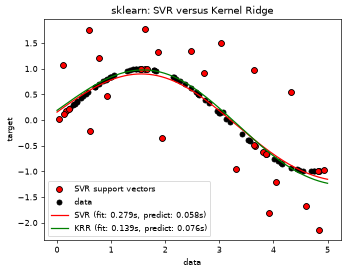

In [2]:
import time
import matplotlib.pyplot as plt
import numpy as np

rng = np.random.RandomState(42)
X = 5 * rng.rand(10000, 1)
y = np.sin(X).ravel()
y[::5] += 3 * (0.5 - rng.rand(X.shape[0] // 5))
X_plot = np.linspace(0, 5, 100000)[:, None]

from sklearn.kernel_ridge import KernelRidge
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR

train_size = 100
svr = GridSearchCV(
    SVR(kernel="rbf", gamma=0.1),
    param_grid={"C": [1e0, 1e1, 1e2, 1e3], "gamma": np.logspace(-2, 2, 5)},
)
kr = GridSearchCV(
    KernelRidge(kernel="rbf", gamma=0.1),
    param_grid={"alpha": [1e0, 0.1, 1e-2, 1e-3], "gamma": np.logspace(-2, 2, 5)},
)
t0 = time.time()
svr.fit(X[:train_size], y[:train_size])
svr_fit = time.time() - t0
print(f"Best SVR with params: {svr.best_params_} and R2 score: {svr.best_score_:.3f}")
t0 = time.time()
kr.fit(X[:train_size], y[:train_size])
kr_fit = time.time() - t0
print(f"Best KRR with params: {kr.best_params_} and R2 score: {kr.best_score_:.3f}")
sv_ratio = svr.best_estimator_.support_.shape[0] / train_size
print("Support vector ratio: %.3f" % sv_ratio)
t0 = time.time()
y_svr = svr.predict(X_plot)
svr_predict = time.time() - t0
t0 = time.time()
y_kr = kr.predict(X_plot)
kr_predict = time.time() - t0

sv_ind = svr.best_estimator_.support_
plt.figure(dpi=60)
plt.scatter(X[sv_ind], y[sv_ind], c="r", s=50, label="SVR support vectors", zorder=2, edgecolors=(0, 0, 0))
plt.scatter(X[:100], y[:100], c="k", label="data", zorder=1, edgecolors=(0, 0, 0))
plt.plot(X_plot, y_svr, c="r", label="SVR (fit: %.3fs, predict: %.3fs)" % (svr_fit, svr_predict))
plt.plot(X_plot, y_kr, c="g", label="KRR (fit: %.3fs, predict: %.3fs)" % (kr_fit, kr_predict))
plt.xlabel("data"); plt.ylabel("target"); plt.title("sklearn: SVR versus Kernel Ridge")
_ = plt.legend()
plt.show()
nb.share(X=X, y=y, X_plot=X_plot)

## 2. Moxie (native Mojo): the same grid searches

In [3]:
%%mojo search
from numojo import NDArray, Shape, Item
from moxie.kernel_ridge import KernelRidge
from moxie.svm import SVR
from moxie.model_selection import GridSearchCV, IndexArray, IndexSplit, KFold, SearchAdapter, SearchScorer
from moxie.model_selection._split import _rows
from moxie_nb_io import load, save, save_floats, save_ints
from std.time import perf_counter_ns

comptime Dense = NDArray[DType.float64]


def kfold(n: Int) raises -> List[IndexSplit]:
    var cursor = KFold(5).split(n)
    var out = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        out.append(pair.value().copy())
    return out^


struct KRR2(SearchScorer):
    """GridSearchCV's default scorer for a regressor: estimator.score (R2)."""
    comptime Estimator = KernelRidge[]
    comptime Input = Dense
    comptime Target = Dense
    comptime Metadata = NoneType

    def __init__(out self):
        pass

    def __init__(out self, *, copy: Self):
        pass

    def score(self, estimator: KernelRidge[], X: Dense, y: Dense, metadata: NoneType) raises -> Float64:
        return estimator.score(X, y)


struct KRRSearch(SearchAdapter):
    comptime Scorer = KRR2
    comptime Value = Float64

    def __init__(out self):
        pass

    def __init__(out self, *, copy: Self):
        pass

    def n_samples(self, X: Dense, y: Dense) raises -> Int:
        return y.shape[0]

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: Dense, rows: IndexArray) raises -> Dense:
        return _rows(y, rows)

    def metadata_rows(self, metadata: NoneType, rows: IndexArray) raises -> NoneType:
        return None

    def fit(self, mut estimator: KernelRidge[], X: Dense, y: Dense, metadata: NoneType) raises:
        _ = estimator.fit(X, y)

    def configure(self, mut estimator: KernelRidge[], params: Dict[String, Float64]) raises:
        # KernelRidge's typed parameter mapping; unknown names raise.
        var mapping = KernelRidge[].ParameterMap()
        for key in params.keys():
            mapping[key] = KernelRidge[].ParameterValue(params[key])
        _ = estimator.set_params(mapping)

    def default_scorer(self) raises -> KRR2:
        return KRR2()

    def default_cv(self, X: Dense, y: Dense) raises -> List[IndexSplit]:
        return kfold(y.shape[0])


struct SVR2(SearchScorer):
    comptime Estimator = SVR
    comptime Input = Dense
    comptime Target = Dense
    comptime Metadata = NoneType

    def __init__(out self):
        pass

    def __init__(out self, *, copy: Self):
        pass

    def score(self, estimator: SVR, X: Dense, y: Dense, metadata: NoneType) raises -> Float64:
        return estimator.score(X, y)


struct SVRSearch(SearchAdapter):
    comptime Scorer = SVR2
    comptime Value = Float64

    def __init__(out self):
        pass

    def __init__(out self, *, copy: Self):
        pass

    def n_samples(self, X: Dense, y: Dense) raises -> Int:
        return y.shape[0]

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: Dense, rows: IndexArray) raises -> Dense:
        return _rows(y, rows)

    def metadata_rows(self, metadata: NoneType, rows: IndexArray) raises -> NoneType:
        return None

    def fit(self, mut estimator: SVR, X: Dense, y: Dense, metadata: NoneType) raises:
        _ = estimator.fit(X, y)

    def configure(self, mut estimator: SVR, params: Dict[String, Float64]) raises:
        var config = estimator.get_params()
        for key in params.keys():
            if key == "C":
                config.C = params[key]
            elif key == "gamma":
                config.gamma = params[key]
            else:
                raise Error("ValueError: Invalid parameter " + key)
        _ = estimator.set_params(config)

    def default_scorer(self) raises -> SVR2:
        return SVR2()

    def default_cv(self, X: Dense, y: Dense) raises -> List[IndexSplit]:
        return kfold(y.shape[0])


def main() raises:
    var X = load("X")
    var y = load("y")
    var X_plot = load("X_plot")
    var rows = IndexArray(Shape(100))
    for i in range(100):
        rows[Item(i)] = Int64(i)
    var Xt = _rows(X, rows)
    var yt = _rows(y, rows)
    var gammas: List[Float64] = [0.01, 0.1, 1.0, 10.0, 100.0]

    var kgrid = Dict[String, List[Float64]]()
    kgrid["alpha"] = [1.0, 0.1, 0.01, 0.001]
    kgrid["gamma"] = gammas.copy()
    var kr = GridSearchCV[KRRSearch](KernelRidge(kernel="rbf", gamma=0.1), kgrid, KRRSearch())
    var t0 = perf_counter_ns()
    kr.fit(Xt, yt, None, None)
    var kr_fit = Float64(perf_counter_ns() - t0) / 1e9
    t0 = perf_counter_ns()
    var y_kr = kr.best_estimator_().predict(X_plot)[Dense].copy()
    var kr_predict = Float64(perf_counter_ns() - t0) / 1e9
    save("kr_mean_test_score", kr.cv_results_().mean_test_score)
    save("kr_rank", kr.cv_results_().rank_test_score)
    save_floats("kr_best", [kr.best_params_()["alpha"], kr.best_params_()["gamma"], kr.best_score_()])
    save("kr_plot", y_kr)
    save("kr_dual_coef", kr.best_estimator_().dual_coef_[Dense])

    var sgrid = Dict[String, List[Float64]]()
    sgrid["C"] = [1.0, 10.0, 100.0, 1000.0]
    sgrid["gamma"] = gammas.copy()
    var svr = GridSearchCV[SVRSearch](SVR(kernel="rbf", gamma=0.1), sgrid, SVRSearch())
    t0 = perf_counter_ns()
    svr.fit(Xt, yt, None, None)
    var svr_fit = Float64(perf_counter_ns() - t0) / 1e9
    t0 = perf_counter_ns()
    var y_svr = svr.best_estimator_().predict(X_plot)
    var svr_predict = Float64(perf_counter_ns() - t0) / 1e9
    save("svr_mean_test_score", svr.cv_results_().mean_test_score)
    save_floats("svr_best", [svr.best_params_()["C"], svr.best_params_()["gamma"], svr.best_score_()])
    save("svr_plot", y_svr)
    save("svr_support", svr.best_estimator_().support_)
    save_floats("times", [svr_fit, svr_predict, kr_fit, kr_predict])
    print("Best KRR alpha", kr.best_params_()["alpha"], "gamma", kr.best_params_()["gamma"], "R2", kr.best_score_())
    print("Best SVR C", svr.best_params_()["C"], "gamma", svr.best_params_()["gamma"], "R2", svr.best_score_())

Best KRR alpha 0.1 gamma 0.1 R2 0.7225015197369407
Best SVR C 1.0 gamma 0.1 R2 0.737255897704102


## 3. Side by side and parity: grid searches

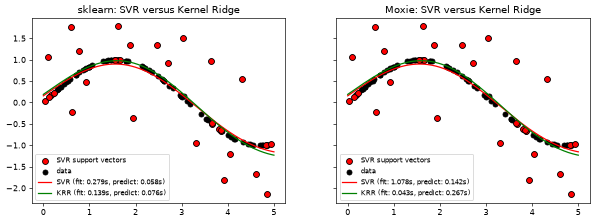

True

In [4]:
mx = nb.results["search"]
t = mx["times"]
sv = mx["svr_support"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=60, sharey=True)
for ax, title, ys, yk, sup, times in ((axes[0], "sklearn", y_svr, y_kr, sv_ind, (svr_fit, svr_predict, kr_fit, kr_predict)),
                                       (axes[1], "Moxie", mx["svr_plot"], mx["kr_plot"], sv, t)):
    ax.scatter(X[sup], y[sup], c="r", s=50, label="SVR support vectors", zorder=2, edgecolors=(0, 0, 0))
    ax.scatter(X[:100], y[:100], c="k", label="data", zorder=1, edgecolors=(0, 0, 0))
    ax.plot(X_plot, ys, c="r", label="SVR (fit: %.3fs, predict: %.3fs)" % tuple(times[:2]))
    ax.plot(X_plot, yk, c="g", label="KRR (fit: %.3fs, predict: %.3fs)" % tuple(times[2:]))
    ax.set_title(title + ": SVR versus Kernel Ridge"); ax.legend(fontsize=8)
plt.show()

moxie_nb.side_by_side(
    sklearn_KRR_best=[kr.best_params_["alpha"], kr.best_params_["gamma"], kr.best_score_],
    moxie_KRR_best=list(mx["kr_best"]),
    sklearn_SVR_best=[svr.best_params_["C"], svr.best_params_["gamma"], svr.best_score_],
    moxie_SVR_best=list(mx["svr_best"]))

CHOL = ("same Float64 Cholesky solve of (K + alpha I); LAPACK blocking and Moxie's kernel/triangular-solve "
        "summation order differ, amplified by cond(K + alpha I) up to ~1e5 for alpha=1e-3 (family Float64 bound 3e-9 "
        "on well-conditioned fixtures)")
nb.compare("KRR GridSearchCV mean_test_score (20 candidates)", kr.cv_results_["mean_test_score"],
           mx["kr_mean_test_score"][:, 0], rtol=1e-7, atol=1e-9, reason=CHOL)
nb.compare("KRR rank_test_score", kr.cv_results_["rank_test_score"], mx["kr_rank"][:, 0], exact=True)
nb.compare("KRR best alpha, gamma", [kr.best_params_["alpha"], kr.best_params_["gamma"]], mx["kr_best"][:2], exact=True)
nb.compare("KRR best_score_", [kr.best_score_], mx["kr_best"][2:], rtol=1e-9, reason=CHOL)
nb.compare("KRR best_estimator_.dual_coef_", kr.best_estimator_.dual_coef_, mx["kr_dual_coef"], rtol=1e-7, atol=1e-9, reason=CHOL)
nb.compare("KRR predict(X_plot), 100000 points", y_kr, mx["kr_plot"], rtol=1e-9, atol=1e-10, reason=CHOL)
SMO = ("same LIBSVM epsilon-SVR SMO in Float64, tol=1e-3; kernel sums use a different order, so converged duals "
       "differ by rounding (svm family parity bound rtol 3e-5 / atol 3e-6); the SVR part is the svm family's surface")
nb.compare("SVR GridSearchCV mean_test_score (20 candidates)", svr.cv_results_["mean_test_score"],
           mx["svr_mean_test_score"][:, 0], rtol=3e-5, atol=3e-6, reason=SMO)
nb.note("cv_results_ score arrays", "ADAPTED",
        "Moxie stores mean/std/rank as (candidate, metric) (documented in model_selection search.md); "
        "the single metric column is compared")
nb.compare("SVR best C, gamma", [svr.best_params_["C"], svr.best_params_["gamma"]], mx["svr_best"][:2], exact=True)
nb.compare("SVR best_estimator_.support_", sv_ind, sv, exact=True)
nb.compare("SVR predict(X_plot)", y_svr, mx["svr_plot"], rtol=3e-5, atol=3e-6, reason=SMO)

## 4. Timing sweep (reduced sizes) and learning curves

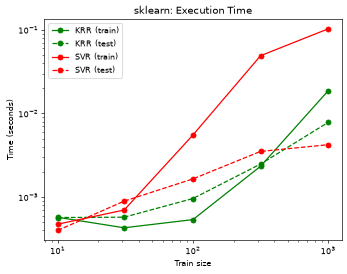

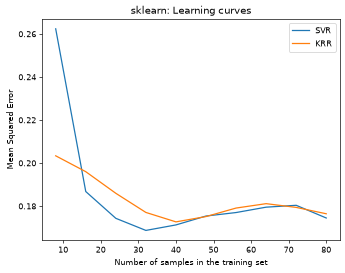

In [5]:
sizes = np.logspace(1, 3, 5).astype(int)
sk_timing = {}
plt.figure(dpi=60)
for name, estimator in {
    "KRR": KernelRidge(kernel="rbf", alpha=0.01, gamma=10),
    "SVR": SVR(kernel="rbf", C=1e2, gamma=10),
}.items():
    train_time, test_time, preds = [], [], []
    for train_test_size in sizes:
        t0 = time.time()
        estimator.fit(X[:train_test_size], y[:train_test_size])
        train_time.append(time.time() - t0)
        t0 = time.time()
        preds.append(estimator.predict(X_plot[:1000]))
        test_time.append(time.time() - t0)
    sk_timing[name] = (train_time, test_time, np.array(preds))
    plt.plot(sizes, train_time, "o-", color="r" if name == "SVR" else "g", label="%s (train)" % name)
    plt.plot(sizes, test_time, "o--", color="r" if name == "SVR" else "g", label="%s (test)" % name)
plt.xscale("log"); plt.yscale("log"); plt.xlabel("Train size"); plt.ylabel("Time (seconds)")
plt.title("sklearn: Execution Time"); _ = plt.legend(loc="best")
plt.show()

from sklearn.model_selection import LearningCurveDisplay, learning_curve
_, ax = plt.subplots(dpi=60)
svr_lc = SVR(kernel="rbf", C=1e1, gamma=0.1)
kr_lc = KernelRidge(kernel="rbf", alpha=0.1, gamma=0.1)
common_params = {
    "X": X[:100], "y": y[:100], "train_sizes": np.linspace(0.1, 1, 10),
    "scoring": "neg_mean_squared_error", "negate_score": True, "score_name": "Mean Squared Error",
    "score_type": "test", "std_display_style": None, "ax": ax,
}
LearningCurveDisplay.from_estimator(svr_lc, **common_params)
LearningCurveDisplay.from_estimator(kr_lc, **common_params)
ax.set_title("sklearn: Learning curves")
ax.legend(handles=ax.get_legend_handles_labels()[0], labels=["SVR", "KRR"])
plt.show()
# The numbers behind the KRR curve, for parity.
lc_sizes, lc_train, lc_test = learning_curve(kr_lc, X[:100], y[:100], train_sizes=np.linspace(0.1, 1, 10),
                                             scoring="neg_mean_squared_error")
nb.share(sizes=sizes.astype(np.int64))

In [6]:
%%mojo timing
from numojo import NDArray, Shape, Item
from moxie.base import SupervisedEstimator, Predictor
from moxie.kernel_ridge import KernelRidge
from moxie.svm import SVR
from moxie.model_selection import IndexArray, IndexSplit, KFold, learning_curve
from moxie.model_selection._evaluation import TypedScorer
from moxie.model_selection._validation import CVAdapter
from moxie.model_selection._split import _rows
from moxie_nb_io import load, load_ints, save, save_floats, save_ints
from std.time import perf_counter_ns

comptime Dense = NDArray[DType.float64]


def head(X: Dense, n: Int) raises -> Dense:
    var rows = IndexArray(Shape(n))
    for i in range(n):
        rows[Item(i)] = Int64(i)
    return _rows(X, rows)


struct NegMSE(TypedScorer):
    """The "neg_mean_squared_error" scorer of sklearn for KernelRidge (no Moxie metrics module)."""
    comptime Estimator = KernelRidge[]
    comptime Input = Dense
    comptime Target = Dense
    comptime Metadata = NoneType

    def __init__(out self):
        pass

    def score(self, estimator: KernelRidge[], X: Dense, y: Dense, metadata: NoneType) raises -> Float64:
        var p = estimator.predict(X)[Dense].copy()
        var total = Float64(0)
        for i in range(y.size):
            total += (y.item(i) - p.item(i)) ** 2
        return -total / Float64(y.size)


struct Rows(CVAdapter):
    comptime Scorer = NegMSE

    def __init__(out self):
        pass

    def n_samples(self, X: Dense, y: Dense) raises -> Int:
        return y.shape[0]

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: Dense, rows: IndexArray) raises -> Dense:
        return _rows(y, rows)

    def metadata_rows(self, metadata: NoneType, rows: IndexArray) raises -> NoneType:
        return None

    def fit(self, mut estimator: KernelRidge[], X: Dense, y: Dense, metadata: NoneType) raises:
        _ = estimator.fit(X, y)


def main() raises:
    var X = load("X")
    var y = load("y")
    var X_query = head(load("X_plot"), 1000)
    var sizes = load_ints("sizes")
    var krr_times = List[Float64]()
    var svr_times = List[Float64]()
    for s in range(len(sizes)):
        var n = sizes[s]
        var Xn = head(X, n)
        var yn = head(y, n)
        var krr = KernelRidge(kernel="rbf", alpha=0.01, gamma=10.0)
        var t0 = perf_counter_ns()
        _ = krr.fit(Xn, yn)
        krr_times.append(Float64(perf_counter_ns() - t0) / 1e9)
        t0 = perf_counter_ns()
        save("krr_" + String(s), krr.predict(X_query)[Dense].copy())
        krr_times.append(Float64(perf_counter_ns() - t0) / 1e9)
        var svr = SVR(kernel="rbf", C=1e2, gamma=10.0)
        t0 = perf_counter_ns()
        _ = svr.fit(Xn, yn)
        svr_times.append(Float64(perf_counter_ns() - t0) / 1e9)
        t0 = perf_counter_ns()
        save("svr_" + String(s), svr.predict(X_query))
        svr_times.append(Float64(perf_counter_ns() - t0) / 1e9)
    save_floats("krr_times", krr_times)
    save_floats("svr_times", svr_times)

    # learning_curve(KernelRidge(alpha=0.1, gamma=0.1), X[:100], y[:100], train_sizes=linspace(0.1, 1, 10)).
    var X100 = head(X, 100)
    var y100 = head(y, 100)
    var cursor = KFold(5).split(100)
    var splits = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        splits.append(pair.value().copy())
    var fractions = Dense(Shape(10))
    for i in range(10):
        fractions[Item(i)] = 0.1 + Float64(i) * 0.1
    var lc = learning_curve[Rows](KernelRidge(kernel="rbf", alpha=0.1, gamma=0.1), X100, y100, Rows(), NegMSE(),
                                  splits, None, None, train_sizes=fractions^)
    save("lc_sizes", lc.train_sizes)
    save("lc_train", lc.train_scores)
    save("lc_test", lc.test_scores)

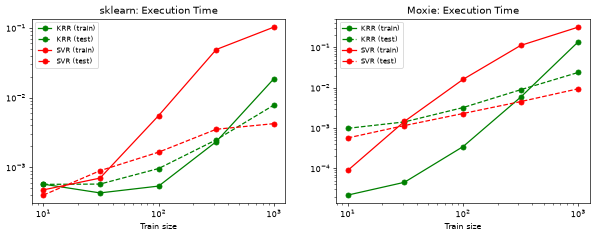

In [7]:
mt = nb.results["timing"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=60)
for name, color in (("KRR", "g"), ("SVR", "r")):
    axes[0].plot(sizes, sk_timing[name][0], "o-", color=color, label=f"{name} (train)")
    axes[0].plot(sizes, sk_timing[name][1], "o--", color=color, label=f"{name} (test)")
    times = mt["krr_times" if name == "KRR" else "svr_times"]
    axes[1].plot(sizes, times[0::2], "o-", color=color, label=f"{name} (train)")
    axes[1].plot(sizes, times[1::2], "o--", color=color, label=f"{name} (test)")
for ax, title in zip(axes, ("sklearn", "Moxie")):
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Train size"); ax.set_title(title + ": Execution Time")
    ax.legend(fontsize=8)
plt.show()
moxie_nb.side_by_side(train_sizes=lc_sizes, sklearn_KRR_test_MSE=-lc_test.mean(axis=1),
                      moxie_KRR_test_MSE=-mt["lc_test"].mean(axis=1))

for s, n in enumerate(sizes):
    nb.compare(f"KRR(alpha=0.01, gamma=10) n={n}: predict(X_plot[:1000])", sk_timing["KRR"][2][s], mt[f"krr_{s}"],
               rtol=1e-7, atol=1e-8,
               reason="Float64 Cholesky of K + 0.01 I with narrow rbf (gamma=10); cond grows with n up to ~1e3 * rows, "
                      "so reduction-order differences reach ~1e-9 relative")
    nb.compare(f"SVR(C=100, gamma=10) n={n}: predict(X_plot[:1000])", sk_timing["SVR"][2][s], mt[f"svr_{s}"],
               rtol=3e-5, atol=3e-6, reason=SMO)
nb.compare("learning_curve train_sizes", lc_sizes, mt["lc_sizes"], exact=True)
nb.compare("learning_curve KRR test neg-MSE (10 sizes x 5 folds)", lc_test, mt["lc_test"], rtol=1e-9, atol=1e-12,
           reason="well-conditioned (alpha=0.1) Float64 solve; summation order of solve and MSE differs")
nb.compare("learning_curve KRR train neg-MSE", lc_train, mt["lc_train"], rtol=1e-9, atol=1e-12,
           reason="well-conditioned (alpha=0.1) Float64 solve; summation order of solve and MSE differs")
nb.note("LearningCurveDisplay / SVR learning curve", "ADAPTED",
        "the numbers behind the KRR curve come from model_selection.learning_curve with a Mojo neg-MSE scorer (Moxie has "
        "no metrics module or string scorers, #3 part 3); model_selection's native-SVG LearningCurveDisplay is not "
        "replayed here, and the SVR curve is the svm family's surface")
nb.note("timing", "ADAPTED", "wall-clock times are displayed, not compared; sizes reduced to 10..1000 (see header)")

## 5. Beyond the gallery: every kernel string, precomputed, multi-target, alpha per target, sample_weight

The family's verification focus. `X[:60]` and a two-column target (`sin`, `cos` with the gallery noise) are fitted with
`alpha=[0.1, 0.5]` and a positive vector `sample_weight`. For `sigmoid` and `additive_chi2` the weighted
`K + alpha I` is not positive definite, so the per-target Cholesky has no fallback and both libraries fail (checked);
those two kernels are then fitted with a shared `alpha=0.1`; each kernel keeps the constructor defaults
(`gamma=None` → 1/n_features, `degree=3`, `coef0=1`) except `chi2`, which needs an explicit `gamma` in the reference
too (its estimator passes `gamma=None` to `chi2_kernel`, which then fails). Prediction is on 200 grid points.

In [8]:
from sklearn.metrics.pairwise import rbf_kernel
KERNELS = ["linear", "poly", "polynomial", "rbf", "laplacian", "sigmoid", "cosine", "additive_chi2", "chi2"]
Xk = X[:60]
Yk = np.column_stack([y[:60], np.cos(X[:60, 0]) + (y[:60] - np.sin(X[:60, 0]))])
wk = 0.5 + rng.rand(60)
Xq = np.linspace(0, 5, 200)[:, None]
INDEFINITE = ["sigmoid", "additive_chi2"]  # weighted K + alpha I is not positive definite here
sk_kernels, sk_unequal_fails = {}, []
for k in KERNELS:
    try:
        KernelRidge(alpha=[0.1, 0.5], kernel=k, gamma=0.5 if k == "chi2" else None).fit(Xk, Yk, sample_weight=wk)
        sk_unequal_fails.append(0)
    except np.linalg.LinAlgError as exc:
        print(f"sklearn {k} with alpha=[0.1, 0.5]: LinAlgError {exc}")
        sk_unequal_fails.append(1)
    alpha = 0.1 if k in INDEFINITE else [0.1, 0.5]
    m = KernelRidge(alpha=alpha, kernel=k, gamma=0.5 if k == "chi2" else None).fit(Xk, Yk, sample_weight=wk)
    sk_kernels[k] = (m.dual_coef_, m.predict(Xq), m.score(Xq, np.column_stack([np.sin(Xq[:, 0]), np.cos(Xq[:, 0])])))
try:
    KernelRidge(kernel="chi2").fit(Xk, Yk)
except Exception as exc:
    print("sklearn chi2 with gamma=None:", type(exc).__name__, exc)
# Scalar sample_weight, 1-D target, shared alpha.
m = KernelRidge(alpha=0.3, kernel="rbf", gamma=2.0).fit(Xk, y[:60], sample_weight=2.0)
sk_scalar = (m.dual_coef_, m.predict(Xq))
# Precomputed kernel: fit on (n, n), predict on (m, n).
Ktrain, Kq = rbf_kernel(Xk, gamma=2.0), rbf_kernel(Xq, Xk, gamma=2.0)
mp = KernelRidge(alpha=0.3, kernel="precomputed").fit(Ktrain, y[:60], sample_weight=wk)
sk_pre = (mp.dual_coef_, mp.predict(Kq), mp.n_features_in_)
# Float32 input stays Float32 for named kernels.
m32 = KernelRidge(alpha=0.3, kernel="rbf", gamma=2.0).fit(Xk.astype(np.float32), y[:60].astype(np.float32))
sk_32 = (m32.dual_coef_, m32.predict(Xq.astype(np.float32)))
print("Float32 dual_coef_ dtype:", m32.dual_coef_.dtype)
sk_wscore = m.score(Xq, np.sin(Xq[:, 0]), sample_weight=np.linspace(0.5, 2, 200))
nb.share(Xk=Xk, Yk=Yk, wk=wk, Xq=Xq, Ktrain=Ktrain, Kq=Kq, Xk32=Xk.astype(np.float32), Xq32=Xq.astype(np.float32),
         y60_32=y[:60].astype(np.float32), Ytrue=np.column_stack([np.sin(Xq[:, 0]), np.cos(Xq[:, 0])]),
         sw200=np.linspace(0.5, 2, 200))

sklearn sigmoid with alpha=[0.1, 0.5]: LinAlgError A singular matrix detected: slice(s) [0] are singular.
sklearn additive_chi2 with alpha=[0.1, 0.5]: LinAlgError A singular matrix detected: slice(s) [0] are singular.
sklearn chi2 with gamma=None: UFuncTypeError Cannot cast ufunc 'multiply' output from dtype('O') to dtype('float64') with casting rule 'same_kind'
Float32 dual_coef_ dtype: float32


/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/linear_model/_ridge.py:266: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/linear_model/_ridge.py:266: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(


In [9]:
%%mojo kernels
from numojo import NDArray, Shape, Item
from moxie.kernel_ridge import KernelRidge, ScalarOrVector
from moxie_nb_io import load, save, save_floats, save_ints

comptime Dense = NDArray[DType.float64]


def as_list(a: Dense) raises -> List[Float64]:
    var out = List[Float64]()
    for i in range(a.size):
        out.append(a.item(i))
    return out^


def main() raises:
    var Xk = load("Xk")
    var Yk = load("Yk")
    var w = as_list(load("wk"))
    var Xq = load("Xq")
    var Ytrue = load("Ytrue")
    var kernels: List[String] = ["linear", "poly", "polynomial", "rbf", "laplacian", "sigmoid", "cosine", "additive_chi2", "chi2"]
    var scores = List[Float64]()
    var unequal_fails = List[Int]()
    for k in kernels:
        var gamma: Optional[Float64] = None
        if k == "chi2":
            gamma = 0.5
        var alphas: List[Float64] = [0.1, 0.5]
        try:
            var unequal = KernelRidge(alpha=ScalarOrVector(alphas.copy()), kernel=k, gamma=gamma)
            _ = unequal.fit(Xk, Yk, sample_weight=ScalarOrVector(w.copy()))
            unequal_fails.append(0)
        except e:
            print("moxie", k, "with alpha=[0.1, 0.5]:", e)
            unequal_fails.append(1)
        var alpha = ScalarOrVector(alphas^)
        if k == "sigmoid" or k == "additive_chi2":
            alpha = ScalarOrVector(0.1)
        var m = KernelRidge(alpha=alpha^, kernel=k, gamma=gamma)
        _ = m.fit(Xk, Yk, sample_weight=ScalarOrVector(w.copy()))
        save(k + "_dual", m.dual_coef_[Dense])
        save(k + "_pred", m.predict(Xq)[Dense].copy())
        scores.append(m.score(Xq, Ytrue))
    save_floats("scores", scores)
    save_ints("unequal_fails", unequal_fails)
    try:
        var no_gamma = KernelRidge(kernel="chi2")
        _ = no_gamma.fit(Xk, Yk)
    except e:
        print("moxie chi2 with gamma=None:", e)

    # 1-D target column 0 is y[:60]; scalar sample_weight; shared alpha.
    var y = Dense(Shape(60))
    for i in range(60):
        y[Item(i)] = Yk.item(i, 0)
    var m = KernelRidge(alpha=0.3, kernel="rbf", gamma=2.0)
    _ = m.fit(Xk, y, sample_weight=ScalarOrVector(2.0))
    save("scalar_dual", m.dual_coef_[Dense])
    save("scalar_pred", m.predict(Xq)[Dense].copy())
    save_floats("wscore", [m.score(Xq, column(Ytrue, 0), sample_weight=ScalarOrVector(as_list(load("sw200"))))])

    var mp = KernelRidge(alpha=0.3, kernel="precomputed")
    _ = mp.fit(load("Ktrain"), y, sample_weight=ScalarOrVector(w.copy()))
    save("pre_dual", mp.dual_coef_[Dense])
    save("pre_pred", mp.predict(load("Kq"))[Dense].copy())
    save_ints("pre_nfeat", [mp.n_features_in_])

    var m32 = KernelRidge(alpha=0.3, kernel="rbf", gamma=2.0)
    _ = m32.fit(load[DType.float32]("Xk32"), load[DType.float32]("y60_32"))
    var d32 = m32.dual_coef_.copy()
    print("Float32 dual_coef_ arm is Float32:", d32.isa[NDArray[DType.float32]]())
    save("f32_dual", d32[NDArray[DType.float32]])
    save("f32_pred", m32.predict(load[DType.float32]("Xq32"))[NDArray[DType.float32]].copy())

    try:
        _ = KernelRidge().predict(Xq)
    except e:
        print("unfitted predict:", e)


def column(a: Dense, j: Int) raises -> Dense:
    var out = Dense(Shape(a.shape[0]))
    for i in range(a.shape[0]):
        out[Item(i)] = a.item(i, j)
    return out^

moxie sigmoid with alpha=[0.1, 0.5]: LinAlgError: per-target regularized kernel is not positive definite
moxie additive_chi2 with alpha=[0.1, 0.5]: LinAlgError: per-target regularized kernel is not positive definite
moxie chi2 with gamma=None: ValueError: chi2 requires explicit gamma
Float32 dual_coef_ arm is Float32: True
unfitted predict: NotFittedError: call fit before inference


In [10]:
mk = nb.results["kernels"]
moxie_nb.side_by_side(kernel=KERNELS, sklearn_R2=[sk_kernels[k][2] for k in KERNELS], moxie_R2=list(mk["scores"]))
KREASON = ("Float64 kernel evaluation and per-target Cholesky (unequal alpha) on 60 rows; kernel and solve summation "
           "order differ from NumPy/LAPACK (family Float64 bound 3e-9 relative plus absolute)")
for i, k in enumerate(KERNELS):
    nb.compare(f"{k}: dual_coef_ (60x2, {'alpha=0.1' if k in INDEFINITE else 'alpha per target'}, vector sample_weight)", sk_kernels[k][0], mk[f"{k}_dual"],
               rtol=3e-9, atol=3e-9, reason=KREASON)
    nb.compare(f"{k}: predict (200x2)", sk_kernels[k][1], mk[f"{k}_pred"], rtol=3e-9, atol=3e-9, reason=KREASON)
    nb.compare(f"{k}: score (uniform R2)", [sk_kernels[k][2]], [mk["scores"][i]], rtol=1.5e-8, atol=1.5e-8,
               reason="R2 of predictions within the bound above (family score bound 5x)")
nb.compare("unequal alpha without fallback: which kernels fail (sigmoid, additive_chi2)", sk_unequal_fails,
           mk["unequal_fails"], exact=True)
nb.note("chi2 with gamma=None", "PASS", "both fail (sklearn TypeError from chi2_kernel, Moxie ValueError; printed above)")
nb.compare("scalar sample_weight=2.0: dual_coef_ (60,)", sk_scalar[0], mk["scalar_dual"], rtol=3e-9, atol=3e-9, reason=KREASON)
nb.compare("scalar sample_weight=2.0: predict", sk_scalar[1], mk["scalar_pred"], rtol=3e-9, atol=3e-9, reason=KREASON)
nb.compare("weighted score", [sk_wscore], mk["wscore"], rtol=1e-12, atol=1e-12,
           reason="Float64 R2 of predictions within the bound above")
nb.compare("precomputed: dual_coef_", sk_pre[0], mk["pre_dual"], rtol=3e-9, atol=3e-9, reason=KREASON)
nb.compare("precomputed: predict on (m, n)", sk_pre[1], mk["pre_pred"], rtol=3e-9, atol=3e-9, reason=KREASON)
nb.compare("precomputed: n_features_in_", [sk_pre[2]], mk["pre_nfeat"], exact=True)
nb.compare("Float32: dual_coef_ dtype", [str(sk_32[0].dtype)], [str(mk["f32_dual"].dtype)], exact=True)
nb.compare("Float32: dual_coef_", sk_32[0], mk["f32_dual"], rtol=2e-4, atol=2e-4,
           reason="Float32 Cholesky on both sides; family Float32 estimator bound 2e-4")
nb.compare("Float32: predict", sk_32[1], mk["f32_pred"], rtol=2e-4, atol=2e-4,
           reason="Float32 Cholesky on both sides; family Float32 estimator bound 2e-4")
nb.note("sparse X (CSR/CSC)", "GAP", "deferred in families/kernel_ridge/docs/api-surface.md; not exercised by the gallery")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
KRR GridSearchCV mean_test_score (20 candidates),PASS,"(20,)","(20,)",2.27e-13,3.2e-13,"rtol=1e-07, atol=1e-09",,"same Float64 Cholesky solve of (K + alpha I); LAPACK blocking and Moxie's kernel/triangular-solve summation order differ, amplified by cond(K + alpha I) up to ~1e5 for alpha=1e-3 (family Float64 bound 3e-9 on well-conditioned fixtures)"
KRR rank_test_score,PASS,"(20,)","(20,)",,,exact,0 mismatches,
"KRR best alpha, gamma",PASS,"(2,)","(2,)",,,exact,0 mismatches,
KRR best_score_,PASS,"(1,)","(1,)",7.77e-16,1.08e-15,"rtol=1e-09, atol=0",,"same Float64 Cholesky solve of (K + alpha I); LAPACK blocking and Moxie's kernel/triangular-solve summation order differ, amplified by cond(K + alpha I) up to ~1e5 for alpha=1e-3 (family Float64 bound 3e-9 on well-conditioned fixtures)"
KRR best_estimator_.dual_coef_,PASS,"(100,)","(100,)",1.58e-13,1.8e-12,"rtol=1e-07, atol=1e-09",,"same Float64 Cholesky solve of (K + alpha I); LAPACK blocking and Moxie's kernel/triangular-solve summation order differ, amplified by cond(K + alpha I) up to ~1e5 for alpha=1e-3 (family Float64 bound 3e-9 on well-conditioned fixtures)"
"KRR predict(X_plot), 100000 points",PASS,"(100000,)","(100000,)",5.22e-14,6.6e-10,"rtol=1e-09, atol=1e-10",,"same Float64 Cholesky solve of (K + alpha I); LAPACK blocking and Moxie's kernel/triangular-solve summation order differ, amplified by cond(K + alpha I) up to ~1e5 for alpha=1e-3 (family Float64 bound 3e-9 on well-conditioned fixtures)"
SVR GridSearchCV mean_test_score (20 candidates),PASS,"(20,)","(20,)",1.11e-16,1.43e-15,"rtol=3e-05, atol=3e-06",,"same LIBSVM epsilon-SVR SMO in Float64, tol=1e-3; kernel sums use a different order, so converged duals differ by rounding (svm family parity bound rtol 3e-5 / atol 3e-6); the SVR part is the svm family's surface"
cv_results_ score arrays,ADAPTED,,,,,,"Moxie stores mean/std/rank as (candidate, metric) (documented in model_selection search.md); the single metric column is compared",
"SVR best C, gamma",PASS,"(2,)","(2,)",,,exact,0 mismatches,
SVR best_estimator_.support_,PASS,"(34,)","(34,)",,,exact,0 mismatches,
